In [1]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency, mannwhitneyu
import matplotlib.pyplot as plt
from scipy.stats import shapiro, f_oneway, kruskal
from sklearn.metrics import roc_auc_score, cohen_kappa_score

In [2]:
data = pd.read_csv("..\datasets\diabetic_data_initial.csv")

In [3]:
def data_overview(x):
 pd.set_option("display.max_columns",50)
 pd.set_option("display.max_rows", None)
 display(x.head(50))
 print(f"Number of rows:{x.shape[0]}\nNumber of columns:{x.shape[1]}")
 print(pd.DataFrame({
     "Data type:": x.dtypes,
     "Missing values:": x.isna().sum(), 
     "Percentage of na:": x.isna().mean()*100,
     "Value count:":  x.nunique()
 }))

In [10]:
data_overview(data)

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,0
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,0
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,0
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,0
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,0
5,35754,82637451,Caucasian,Male,[50-60),NaN,2,1,2,3,NaN,NaN,31,6,16,0,0,0,414,411,250,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,0
6,55842,84259809,Caucasian,Male,[60-70),NaN,3,1,2,4,NaN,NaN,70,1,21,0,0,0,414,411,V45,7,NaN,NaN,Steady,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,0
7,63768,114882984,Caucasian,Male,[70-80),NaN,1,1,7,5,NaN,NaN,73,0,12,0,0,0,428,492,250,8,NaN,NaN,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,0
8,12522,48330783,Caucasian,Female,[80-90),NaN,2,1,4,13,NaN,NaN,68,2,28,0,0,0,398,427,38,8,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,0
9,15738,63555939,Caucasian,Female,[90-100),NaN,3,3,4,12,NaN,InternalMedicine,33,3,18,0,0,0,434,198,486,8,NaN,NaN,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,0


Number of rows:101766
Number of columns:50
                         Data type:  Missing values:  Percentage of na:  \
encounter_id                  int64                0           0.000000   
patient_nbr                   int64                0           0.000000   
race                         object             2273           2.233555   
gender                       object                0           0.000000   
age                          object                0           0.000000   
weight                       object            98569          96.858479   
admission_type_id             int64                0           0.000000   
discharge_disposition_id      int64                0           0.000000   
admission_source_id           int64                0           0.000000   
time_in_hospital              int64                0           0.000000   
payer_code                   object            40256          39.557416   
medical_specialty            object            49949     

U skupu podataka uocava se string "?" koji predstavlja nedostajucu vrednost, ali je python tako ne prepoznaje pa ce "?" biti zamenjen sa NaN

In [5]:
data["readmitted_original"] = data["readmitted"]
data["readmitted"] = (data["readmitted"] == "<30").astype(int)

In [6]:
data.drop(columns=["readmitted_original"], inplace=True)

In [7]:
print(data["readmitted"].value_counts())
print(data["readmitted"].value_counts(normalize=True) * 100)

readmitted
0    90409
1    11357
Name: count, dtype: int64
readmitted
0    88.840084
1    11.159916
Name: proportion, dtype: float64


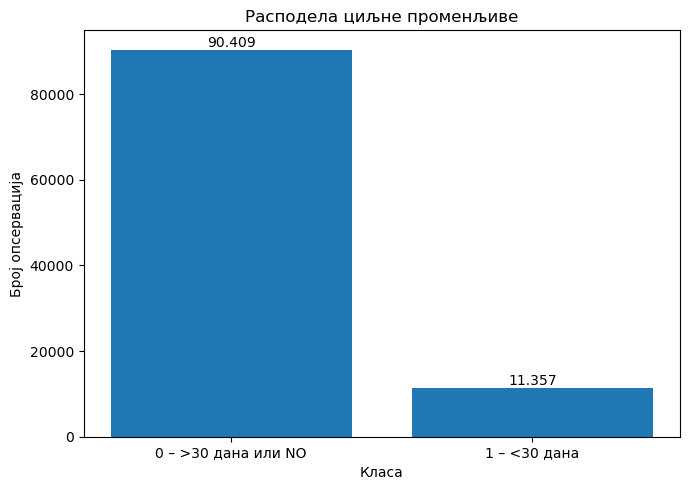

In [8]:
import matplotlib.pyplot as plt

counts = data["readmitted"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
bars = plt.bar(["0 – >30 дана или NO", "1 – <30 дана"], counts.values)

plt.xlabel("Класа")
plt.ylabel("Број опсервација")
plt.title("Расподела циљне променљиве")

for bar, value in zip(bars, counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}".replace(",", "."),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [8]:
def replacing_with_na(x):
   missing_value = "?"
   for column in x.columns:
        x[column]= x[column].replace(missing_value, np.nan)
   return x

In [9]:
data = replacing_with_na(data)

Kolone "weight" i "max_glu_serum" imaju visok procenat nedostajucih vrednosti(>94%). Osim toga, A1Cresult i medical_specialty sadrze visok procenat nedostajucih vrednosti, sto ce biti uzeto u obzir u daljim analizama. 

In [11]:
data["weight"].describe()

count         3197
unique           9
top       [75-100)
freq          1336
Name: weight, dtype: object

In [12]:
data["max_glu_serum"].describe()

count     5346
unique       3
top       Norm
freq      2597
Name: max_glu_serum, dtype: object

In [13]:
data = data.drop(["weight","max_glu_serum"], axis = 1)

In [14]:
data_id_mapping = pd.read_csv("../datasets/id_mapping.csv")

In [15]:
data_overview(data_id_mapping)

,ID mappings for the diabetes dataset,? - always means a missing value
0,admission_type_id,description
1,1,Emergency
2,2,Urgent
3,3,Elective
4,4,Newborn
5,5,Not Available
6,6,NaN
7,7,Trauma Center
8,8,Not Mapped
9,NaN,NaN


Number of rows:68
Number of columns:2
                                     Data type:  Missing values:  \
ID mappings for the diabetes dataset     object                2   
 ? - always means a missing value        object                5   

                                      Percentage of na:  Value count:  
ID mappings for the diabetes dataset           2.941176            33  
 ? - always means a missing value              7.352941            56  


Pored standardnih nedostajucih vrednosti potrebno je analizirati i tabelu id_mapping.csv i proveriti da li postoje sifre koje se takodje mogu tretirati kao NaN.

In [16]:
data_id_mapping.columns

Index(['ID mappings for the diabetes dataset', ' ? - always means a missing value'], dtype='object')

In [17]:
admission_mapping = data_id_mapping[0:9]

In [18]:
admission_mapping.head(12)

,ID mappings for the diabetes dataset,? - always means a missing value
0,admission_type_id,description
1,1,Emergency
2,2,Urgent
3,3,Elective
4,4,Newborn
5,5,Not Available
6,6,NaN
7,7,Trauma Center
8,8,Not Mapped


In [19]:
admission_mapping.columns= admission_mapping.iloc[0]

In [20]:
admission_mapping= admission_mapping[1:].reset_index(drop=True)

In [21]:
discharge_disposition_mapping = data_id_mapping[10:41]

In [22]:
discharge_disposition_mapping.head(40)

,ID mappings for the diabetes dataset,? - always means a missing value
10,discharge_disposition_id,description
11,1,Discharged to home
12,2,Discharged/transferred to another short term h...
13,3,Discharged/transferred to SNF
14,4,Discharged/transferred to ICF
15,5,Discharged/transferred to another type of inpa...
16,6,Discharged/transferred to home with home healt...
17,7,Left AMA
18,8,Discharged/transferred to home under care of H...
19,9,Admitted as an inpatient to this hospital


In [23]:
discharge_disposition_mapping.columns = discharge_disposition_mapping.iloc[0]

In [24]:
discharge_disposition_mapping = discharge_disposition_mapping[1:].reset_index(drop = True)

In [25]:
discharge_disposition_mapping.columns

Index(['discharge_disposition_id', 'description'], dtype='object', name=10)

In [26]:
discharge_disposition_mapping.columns.name = None

In [27]:
admission_source_mapping = data_id_mapping[42:]

In [28]:
admission_source_mapping.head(30)

,ID mappings for the diabetes dataset,? - always means a missing value
42,admission_source_id,description
43,1,Physician Referral
44,2,Clinic Referral
45,3,HMO Referral
46,4,Transfer from a hospital
47,5,Transfer from a Skilled Nursing Facility (SNF)
48,6,Transfer from another health care facility
49,7,Emergency Room
50,8,Court/Law Enforcement
51,9,Not Available


In [29]:
admission_source_mapping.columns = admission_source_mapping.iloc[0]

In [30]:
admission_source_mapping = admission_source_mapping[1:].reset_index(drop=True)

In [31]:
admission_source_mapping.columns.name = None

In [32]:
def data_frame_to_dict(x):
 dictionary = dict(
 zip(
    x[x.columns[0]].astype(int),
    x[x.columns[1]]
 )  
 )
 return dictionary

In [33]:
admission_dict = data_frame_to_dict(admission_mapping)

In [34]:
discharge_dict  =data_frame_to_dict(discharge_disposition_mapping)

In [35]:
admission_source_dict = data_frame_to_dict(admission_source_mapping)

In [36]:
data_raw = data.copy()

In [37]:
data["admission_type"]= data["admission_type_id"].map(admission_dict)
data["discharge_disposition"] = data["discharge_disposition_id"].map(discharge_dict)
data["admmission_source"]= data["admission_source_id"].map(admission_source_dict)

In [38]:
data_overview(data)

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,A1Cresult,metformin,repaglinide,nateglinide,...,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,admission_type,discharge_disposition,admmission_source
0,2278392,8222157,Caucasian,Female,[0-10),6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,No,No,No,...,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,0,NaN,Not Mapped,Physician Referral
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,No,No,No,...,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,0,Emergency,Discharged to home,Emergency Room
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,No,No,No,...,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,0,Emergency,Discharged to home,Emergency Room
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,No,No,No,...,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,0,Emergency,Discharged to home,Emergency Room
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,No,No,No,...,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,0,Emergency,Discharged to home,Emergency Room
5,35754,82637451,Caucasian,Male,[50-60),2,1,2,3,NaN,NaN,31,6,16,0,0,0,414,411,250,9,NaN,No,No,No,...,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,0,Urgent,Discharged to home,Clinic Referral
6,55842,84259809,Caucasian,Male,[60-70),3,1,2,4,NaN,NaN,70,1,21,0,0,0,414,411,V45,7,NaN,Steady,No,No,...,Steady,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,0,Elective,Discharged to home,Clinic Referral
7,63768,114882984,Caucasian,Male,[70-80),1,1,7,5,NaN,NaN,73,0,12,0,0,0,428,492,250,8,NaN,No,No,No,...,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,0,Emergency,Discharged to home,Emergency Room
8,12522,48330783,Caucasian,Female,[80-90),2,1,4,13,NaN,NaN,68,2,28,0,0,0,398,427,38,8,NaN,No,No,No,...,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,0,Urgent,Discharged to home,Transfer from a hospital
9,15738,63555939,Caucasian,Female,[90-100),3,3,4,12,NaN,InternalMedicine,33,3,18,0,0,0,434,198,486,8,NaN,No,No,No,...,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,0,Elective,Discharged/transferred to SNF,Transfer from a hospital


Number of rows:101766
Number of columns:51
                         Data type:  Missing values:  Percentage of na:  \
encounter_id                  int64                0           0.000000   
patient_nbr                   int64                0           0.000000   
race                         object             2273           2.233555   
gender                       object                0           0.000000   
age                          object                0           0.000000   
admission_type_id             int64                0           0.000000   
discharge_disposition_id      int64                0           0.000000   
admission_source_id           int64                0           0.000000   
time_in_hospital              int64                0           0.000000   
payer_code                   object            40256          39.557416   
medical_specialty            object            49949          49.082208   
num_lab_procedures            int64                0     

Moze se uociti da su odredjene sifre u kolonama admission_type_id, discharge_disposition_id, admission_source_id, oznacavale nedostajucu vrednost i tako ce nadalje biti tretirane. 

In [39]:
data.drop(["admission_type_id","discharge_disposition_id","admission_source_id"], axis = 1, inplace= True)
data = data[[col for col in data.columns if col != "readmitted"] + ["readmitted"]]

In [40]:
data_overview(data)

,encounter_id,patient_nbr,race,gender,age,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,admission_type,discharge_disposition,admmission_source,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NaN,Not Mapped,Physician Referral,0
1,149190,55629189,Caucasian,Female,[10-20),3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,0
2,64410,86047875,AfricanAmerican,Female,[20-30),2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,Emergency,Discharged to home,Emergency Room,0
3,500364,82442376,Caucasian,Male,[30-40),2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,0
4,16680,42519267,Caucasian,Male,[40-50),1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,0
5,35754,82637451,Caucasian,Male,[50-60),3,NaN,NaN,31,6,16,0,0,0,414,411,250,9,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,Urgent,Discharged to home,Clinic Referral,0
6,55842,84259809,Caucasian,Male,[60-70),4,NaN,NaN,70,1,21,0,0,0,414,411,V45,7,NaN,Steady,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,Elective,Discharged to home,Clinic Referral,0
7,63768,114882984,Caucasian,Male,[70-80),5,NaN,NaN,73,0,12,0,0,0,428,492,250,8,NaN,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,Emergency,Discharged to home,Emergency Room,0
8,12522,48330783,Caucasian,Female,[80-90),13,NaN,NaN,68,2,28,0,0,0,398,427,38,8,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,Urgent,Discharged to home,Transfer from a hospital,0
9,15738,63555939,Caucasian,Female,[90-100),12,NaN,InternalMedicine,33,3,18,0,0,0,434,198,486,8,NaN,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,Elective,Discharged/transferred to SNF,Transfer from a hospital,0


Number of rows:101766
Number of columns:48
                         Data type:  Missing values:  Percentage of na:  \
encounter_id                  int64                0           0.000000   
patient_nbr                   int64                0           0.000000   
race                         object             2273           2.233555   
gender                       object                0           0.000000   
age                          object                0           0.000000   
time_in_hospital              int64                0           0.000000   
payer_code                   object            40256          39.557416   
medical_specialty            object            49949          49.082208   
num_lab_procedures            int64                0           0.000000   
num_procedures                int64                0           0.000000   
num_medications               int64                0           0.000000   
number_outpatient             int64                0     

In [41]:
data["discharge_disposition"].value_counts()

discharge_disposition
Discharged to home                                                                                           60234
Discharged/transferred to SNF                                                                                13954
Discharged/transferred to home with home health service                                                      12902
Discharged/transferred to another short term hospital                                                         2128
Discharged/transferred to another rehab fac including rehab units of a hospital .                             1993
Expired                                                                                                       1642
Discharged/transferred to another type of inpatient care institution                                          1184
Not Mapped                                                                                                     989
Discharged/transferred to ICF                             

In [42]:
remove_disposition = [
    "Expired",
    "Hospice / home",
    "Hospice / medical facility",
    "Expired at home. Medicaid only, hospice.",
    "Expired in a medical facility. Medicaid only, hospice."
]

data["discharge_disposition"].isin(remove_disposition).sum()

np.int64(2423)

In [43]:
data = data[
    ~data["discharge_disposition"].isin(remove_disposition)
]

In [44]:
data.drop("encounter_id", axis= 1, inplace=True)

Atribut "encounter_id" predstavlja jedinstveni identifikator, pa je zbog toga uklonjen iz dalje analize. 

In [45]:
data["patient_nbr"].nunique()

69990

Atribut patient_nbr se za sada zadrzava jer se koristi za grupisanje hospitalizacija istog pacijenta prilikom podele podataka na skupove za treniranje i testiranje. Nece biti koriscen kao ulazni atribut modela.

In [46]:
data.select_dtypes(include="object").nunique().sort_values()

citoglipton                   1
examide                       1
tolbutamide                   2
acetohexamide                 2
diabetesMed                   2
change                        2
metformin-pioglitazone        2
metformin-rosiglitazone       2
glimepiride-pioglitazone      2
glipizide-metformin           2
troglitazone                  2
A1Cresult                     3
gender                        3
tolazamide                    3
miglitol                      4
rosiglitazone                 4
acarbose                      4
pioglitazone                  4
glimepiride                   4
glyburide                     4
glipizide                     4
chlorpropamide                4
nateglinide                   4
repaglinide                   4
metformin                     4
glyburide-metformin           4
insulin                       4
race                          5
admission_type                7
age                          10
admmission_source            16
payer_co

In [47]:
data = data.drop(["citoglipton", "examide"], axis=1)

Atributi citoglipton i examide su uklonjeni jer imaju samo jednu jedinstvenu vrednost u celom skupu podataka i samim tim ne sadrze korisnu informaciju za model. Njihova varijabilnost je jednaka nuli, pa cak ni nakon podele skupa na trening i test nece biti nikakvih promena.

In [48]:
data[["acetohexamide","metformin-pioglitazone","metformin-rosiglitazone","glimepiride-pioglitazone","glipizide-metformin","tolbutamide","troglitazone"]].apply(pd.Series.value_counts)

,acetohexamide,metformin-pioglitazone,metformin-rosiglitazone,glimepiride-pioglitazone,glipizide-metformin,tolbutamide,troglitazone
No,99342,99342,99341,99342,99330,99322,99340
Steady,1,1,2,1,13,21,3


In [49]:
data = data.drop([
     "acetohexamide",
    "metformin-pioglitazone",
    "metformin-rosiglitazone",
    "glimepiride-pioglitazone",
    "glipizide-metformin",
    "tolbutamide",
   "troglitazone"
 ], axis=1) 

Uklanjanje gore navedenih atributa je metodoloski opravdano, iz razloga jer je varijabilnost ekstremno nista, pa cak i nakon podele, varijabilnost ce biti dovoljno niska, da se ovi atributi mogu ukloniti.

In [50]:
data[["tolazamide","repaglinide","metformin","glimepiride","glipizide","glyburide","pioglitazone","acarbose","nateglinide","miglitol","insulin","glyburide-metformin","rosiglitazone","chlorpropamide"]].apply(pd.Series.value_counts)

,tolazamide,repaglinide,metformin,glimepiride,glipizide,glyburide,pioglitazone,acarbose,nateglinide,miglitol,insulin,glyburide-metformin,rosiglitazone,chlorpropamide
Down,NaN,43,574,191,548,560,117,3,11,5,11908,6,85,1
No,99304.0,97825,79499,94221,86812,88820,92088,99038,98654,99305,46379,98645,93039,99258
Steady,38.0,1368,18207,4609,11219,9162,6908,292,654,31,30069,684,6048,78
Up,1.0,107,1063,322,764,801,230,10,24,2,10987,8,171,6


### Analiza numerickih atributa 

In [51]:
numeric_columns = data.select_dtypes(include="number").columns.drop(["patient_nbr", "readmitted"])
data[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,99343.0,4.379332,2.968409,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,99343.0,42.906929,19.610032,1.0,31.0,44.0,57.0,132.0
num_procedures,99343.0,1.334236,1.702786,0.0,0.0,1.0,2.0,6.0
num_medications,99343.0,15.979062,8.094909,1.0,10.0,15.0,20.0,81.0
number_outpatient,99343.0,0.369246,1.265142,0.0,0.0,0.0,0.0,42.0
number_emergency,99343.0,0.198444,0.937734,0.0,0.0,0.0,0.0,76.0
number_inpatient,99343.0,0.630935,1.260428,0.0,0.0,0.0,1.0,21.0
number_diagnoses,99343.0,7.401709,1.941013,1.0,6.0,8.0,9.0,16.0


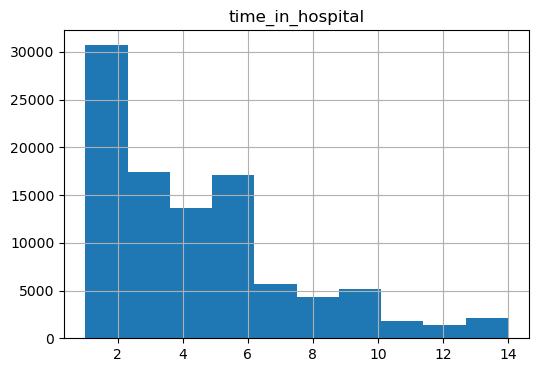

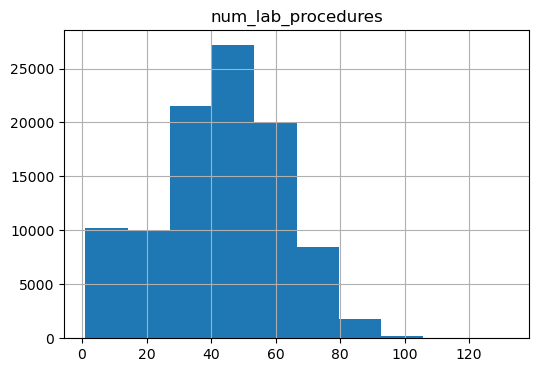

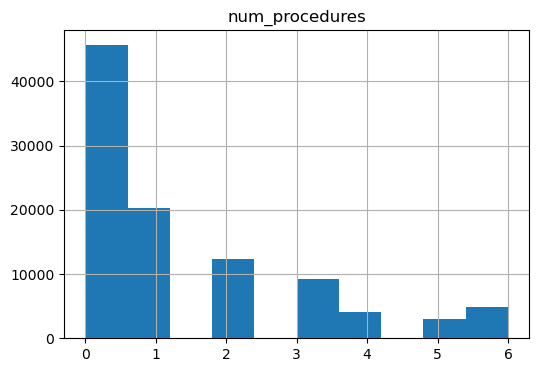

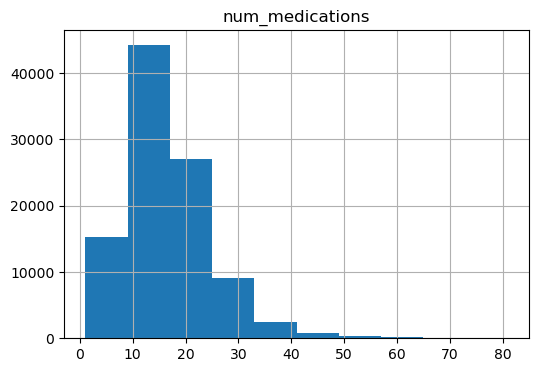

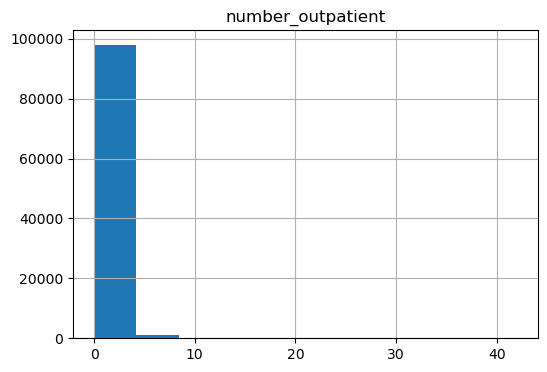

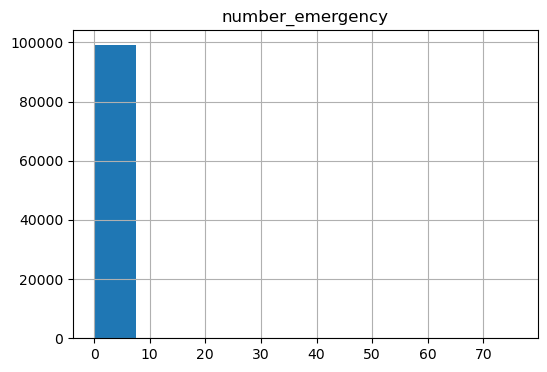

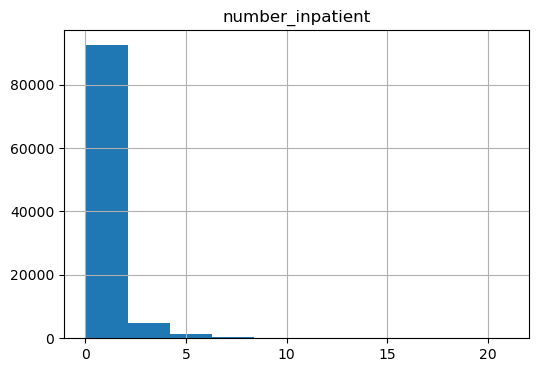

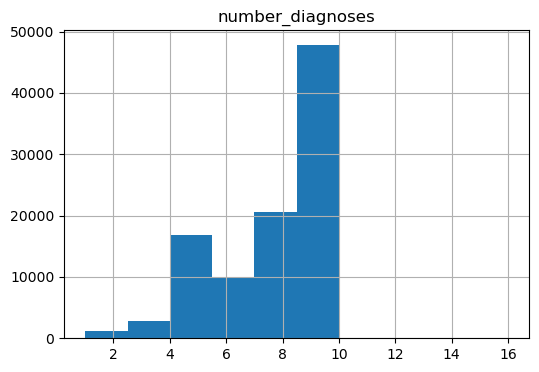

In [52]:
for column in numeric_columns:
        plt.figure(figsize=(6, 4))
        data[column].hist()
        plt.title(column)
        plt.show()

In [53]:
for column in numeric_columns:
    print(f"\n--- {column} ---")
    print(data[column].value_counts().head(10))
    print("Број јединствених вредности:", data[column].nunique())


--- time_in_hospital ---
time_in_hospital
3     17432
2     16891
1     13824
4     13684
5      9749
6      7355
7      5696
8      4271
9      2879
10     2262
Name: count, dtype: int64
Број јединствених вредности: 14

--- num_lab_procedures ---
num_lab_procedures
1     3153
43    2752
44    2447
45    2331
38    2180
40    2163
46    2142
41    2082
42    2066
39    2061
Name: count, dtype: int64
Број јединствених вредности: 118

--- num_procedures ---
num_procedures
0    45679
1    20250
2    12373
3     9203
6     4801
4     4049
5     2988
Name: count, dtype: int64
Број јединствених вредности: 7

--- num_medications ---
num_medications
13    5976
12    5888
11    5696
15    5694
14    5592
16    5324
10    5245
9     4830
17    4801
18    4405
Name: count, dtype: int64
Број јединствених вредности: 75

--- number_outpatient ---
number_outpatient
0    82994
1     8349
2     3509
3     1997
4     1077
5      514
6      294
7      154
8       96
9       82
Name: count, dtype: int64


In [54]:

correlation_matrix = data[numeric_columns].corr(method="spearman")

display(correlation_matrix)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
time_in_hospital,1.000000,0.338932,0.186796,0.463446,-0.013686,-0.000782,0.093031,0.237700
num_lab_procedures,0.338932,1.000000,0.016508,0.248416,-0.023744,0.008058,0.041246,0.165544
num_procedures,0.186796,0.016508,1.000000,0.348619,-0.023753,-0.046510,-0.064419,0.063339
num_medications,0.463446,0.248416,0.348619,1.000000,0.075430,0.045545,0.100765,0.293927
number_outpatient,-0.013686,-0.023744,-0.023753,0.075430,1.000000,0.179225,0.156665,0.113742
number_emergency,-0.000782,0.008058,-0.046510,0.045545,0.179225,1.000000,0.222692,0.093217
number_inpatient,0.093031,0.041246,-0.064419,0.100765,0.156665,0.222692,1.000000,0.136186
number_diagnoses,0.237700,0.165544,0.063339,0.293927,0.113742,0.093217,0.136186,1.000000


In [55]:
corr_matrix = data[numeric_columns].corr()

max_corr = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
).stack().max()

print("Najviša korelacija:", max_corr)

Najviša korelacija: 0.46375689917507834


### Analiza kategorijskih atributa

In [56]:
categorical_atributes = data.select_dtypes(include = "object").columns

In [57]:
for column in categorical_atributes:
    print(f"\n--- {column} ---")
    display(data[column].value_counts(dropna=False))


--- race ---


race
Caucasian          74220
AfricanAmerican    18772
NaN                 2234
Hispanic            2017
Other               1472
Asian                628
Name: count, dtype: int64


--- gender ---


gender
Female             53454
Male               45886
Unknown/Invalid        3
Name: count, dtype: int64


--- age ---


...

admission_type
Emergency        52371
Elective         18668
Urgent           18132
NaN               5207
Not Available     4617
Not Mapped         320
Trauma Center       18
Newborn             10
Name: count, dtype: int64


--- discharge_disposition ---


discharge_disposition
Discharged to home                                                                                           60234
Discharged/transferred to SNF                                                                                13954
Discharged/transferred to home with home health service                                                      12902
NaN                                                                                                           3691
Discharged/transferred to another short term hospital                                                         2128
Discharged/transferred to another rehab fac including rehab units of a hospital .                             1993
Discharged/transferred to another type of inpatient care institution                                          1184
Not Mapped                                                                                                     989
Discharged/transferred to ICF                             


--- admmission_source ---


admmission_source
Emergency Room                                               55850
Physician Referral                                           29168
NaN                                                           6570
Transfer from a hospital                                      3118
Transfer from another health care facility                    2239
Clinic Referral                                               1081
Transfer from a Skilled Nursing Facility (SNF)                 806
HMO Referral                                                   185
Not Mapped                                                     159
Not Available                                                  125
Court/Law Enforcement                                           15
Transfer from hospital inpt/same fac reslt in a sep claim       12
Transfer from critial access hospital                            8
Extramural Birth                                                 2
Normal Delivery                             

In [58]:
data["gender"] = data["gender"].replace("Unknown/Invalid", np.nan)

In [59]:
for threshold in [10, 25, 50, 100]:
    counts = data["medical_specialty"].value_counts()
    print(f"\nPrag {threshold}")
    print("Broj kategorija koje ostaju:", (counts >= threshold).sum())


Prag 10
Broj kategorija koje ostaju: 51

Prag 25
Broj kategorija koje ostaju: 42

Prag 50
Broj kategorija koje ostaju: 34

Prag 100
Broj kategorija koje ostaju: 28


In [60]:
medical_specialty_mapping = {
    # Internal medicine
    "InternalMedicine": "Internal Medicine",
    "Endocrinology": "Internal Medicine",
    "Endocrinology-Metabolism": "Internal Medicine",
    "Nephrology": "Internal Medicine",
    "Pulmonology": "Internal Medicine",
    "Gastroenterology": "Internal Medicine",
    "Hematology": "Internal Medicine",
    "InfectiousDiseases": "Internal Medicine",
    "Rheumatology": "Internal Medicine",
    "Oncology": "Internal Medicine",
    "Hematology/Oncology": "Internal Medicine",

    # Emergency
    "Emergency/Trauma": "Emergency",

    # General practice
    "Family/GeneralPractice": "General Practice",

    # Cardiology
    "Cardiology": "Cardiology",
    "Surgery-Cardiovascular/Thoracic": "Surgery",

    # Surgery
    "Surgery-General": "Surgery",
    "Surgery-Vascular": "Surgery",
    "Surgery-Neuro": "Surgery",
    "Surgery-Thoracic": "Surgery",
    "Surgery-Cardiovascular": "Surgery",
    "Surgery-Plastic": "Surgery",
    "Surgery-Colon&Rectal": "Surgery",
    "Surgery-Maxillofacial": "Surgery",
    "Surgery-Pediatric": "Surgery",
    "Surgery-PlasticwithinHeadandNeck": "Surgery",
    "SurgicalSpecialty": "Surgery",
    "Surgeon": "Surgery",

    # Pediatrics
    "Pediatrics": "Pediatrics",
    "Pediatrics-Endocrinology": "Pediatrics",
    "Pediatrics-CriticalCare": "Pediatrics",
    "Pediatrics-Pulmonology": "Pediatrics",
    "Pediatrics-Neurology": "Pediatrics",
    "Pediatrics-Hematology-Oncology": "Pediatrics",
    "Pediatrics-EmergencyMedicine": "Pediatrics",
    "Pediatrics-AllergyandImmunology": "Pediatrics",
    "Pediatrics-InfectiousDiseases": "Pediatrics",

    #Psychiatry
    "Psychiatry": "Psychiatry",
    "Psychiatry-Child/Adolescent": "Psychiatry",
    "Psychiatry-Addictive": "Psychiatry",

    # Neurology
    "Neurology": "Neurology",
    "Neurophysiology": "Neurology",

    # Radiology
    "Radiologist": "Radiology",
    "Radiology": "Radiology",

    # Obstetrics and gynecology
    "ObstetricsandGynecology": "Obstetrics/Gynecology",
    "Obstetrics": "Obstetrics/Gynecology",
    "Gynecology": "Obstetrics/Gynecology",
    "Obsterics&Gynecology-GynecologicOnco": "Obstetrics/Gynecology",
    "Perinatology": "Obstetrics/Gynecology"

    
}

In [61]:
unmapped = set(data["medical_specialty"].unique()) - set(medical_specialty_mapping.keys())

print("Broj nemapiranih:", len(unmapped))
print(unmapped)

Broj nemapiranih: 25
{'Cardiology-Pediatric', 'Podiatry', 'Anesthesiology', 'OutreachServices', 'AllergyandImmunology', 'Otolaryngology', 'Dentistry', 'Anesthesiology-Pediatric', 'PhysicalMedicineandRehabilitation', 'Orthopedics', 'Pathology', 'SportsMedicine', 'Orthopedics-Reconstructive', 'Proctology', 'Ophthalmology', 'Speech', 'Hospitalist', 'DCPTEAM', 'Resident', nan, 'PhysicianNotFound', 'Dermatology', 'Psychology', 'Osteopath', 'Urology'}


In [62]:
additional_mapping = {
    "Urology": "Urology",
    "Psychology": "Psychology",
    "Orthopedics": "Orthopedics",
    "Orthopedics-Reconstructive": "Orthopedics",
    "Podiatry": "Orthopedics",
    "DCPTEAM": "Other",
    "AllergyandImmunology": "Other",
    "SportsMedicine": "Orthopedics",
    "Hospitalist": "Internal Medicine",
    "Dermatology": "Other",
    "Otolaryngology": "Other",
    "PhysicalMedicineandRehabilitation": "Physical Medicine/Rehabilitation",
    "Dentistry": "Other",
    "Pathology": "Other",
    "Cardiology-Pediatric": "Cardiology",
    "Proctology": "Surgery",
    "Anesthesiology-Pediatric": "Anesthesiology",
    "Speech": "Other",
    "Orthopedics-Reconstructive": "Orthopedics",
    "Anesthesiology": "Anesthesiology",
    "OutreachServices": "Other",
    "Osteopath": "Other",
    "PhysicianNotFound": "Other",
    "Ophthalmology": "Other",
    "Resident": "Other"
}

In [63]:
medical_specialty_mapping.update(additional_mapping)

In [64]:
unmapped = set(data["medical_specialty"].unique()) - set(medical_specialty_mapping.keys())

print("Broj nemapiranih kategorija:", len(unmapped))
print(unmapped)

Broj nemapiranih kategorija: 1
{nan}


In [65]:
data["medical_specialty_group"] = (
    data["medical_specialty"].map(medical_specialty_mapping)
)

In [66]:
data["medical_specialty_group"].value_counts()

medical_specialty_group
Internal Medicine                   17987
Emergency                            7419
General Practice                     7252
Cardiology                           5286
Surgery                              5042
Orthopedics                          2723
Radiology                            1174
Psychiatry                            861
Obstetrics/Gynecology                 772
Urology                               682
Pediatrics                            545
Physical Medicine/Rehabilitation      391
Other                                 259
Neurology                             202
Psychology                            101
Anesthesiology                         31
Name: count, dtype: int64

In [67]:
data = data.drop(columns=["medical_specialty"])

cols = [col for col in data.columns if col != "readmitted"] + ["readmitted"]
data = data[cols]

In [68]:
data["admission_type"] = data["admission_type"].replace({
    "Not Available": "Unknown",
    "Not Mapped": "Unknown"
})

data["admission_type"] = data["admission_type"].fillna("Unknown")

In [69]:
discharge_mapping = {
     "Not Mapped": "Unknown" }
data["discharge_disposition"] = data["discharge_disposition"].replace(discharge_mapping)
data["discharge_disposition"] = data["discharge_disposition"].fillna("Unknown")

In [70]:
admission_source_mapping = {
    "Not Mapped": "Unknown",
    "Not Available": "Unknown"
 }
data["admmission_source"] = data["admmission_source"].replace(
     admission_source_mapping
 )

data["admmission_source"] = data["admmission_source"].fillna("Unknown")

In [71]:
 for column in ["admission_type", "discharge_disposition", "admmission_source"]:
    print(f"\n--- {column} ---")
    print(data[column].value_counts(dropna=False))


--- admission_type ---
admission_type
Emergency        52371
Elective         18668
Urgent           18132
Unknown          10144
Trauma Center       18
Newborn             10
Name: count, dtype: int64

--- discharge_disposition ---
discharge_disposition
Discharged to home                                                                                           60234
Discharged/transferred to SNF                                                                                13954
Discharged/transferred to home with home health service                                                      12902
Unknown                                                                                                       4680
Discharged/transferred to another short term hospital                                                         2128
Discharged/transferred to another rehab fac including rehab units of a hospital .                             1993
Discharged/transferred to another type of inpatient ca

In [72]:
data_overview(data)

,patient_nbr,race,gender,age,time_in_hospital,payer_code,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,glipizide,glyburide,pioglitazone,rosiglitazone,acarbose,miglitol,tolazamide,insulin,glyburide-metformin,change,diabetesMed,admission_type,discharge_disposition,admmission_source,medical_specialty_group,readmitted
0,8222157,Caucasian,Female,[0-10),1,NaN,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Unknown,Unknown,Physician Referral,Pediatrics,0
1,55629189,Caucasian,Female,[10-20),3,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,NaN,0
2,86047875,AfricanAmerican,Female,[20-30),2,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,Yes,Emergency,Discharged to home,Emergency Room,NaN,0
3,82442376,Caucasian,Male,[30-40),2,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,NaN,0
4,42519267,Caucasian,Male,[40-50),1,NaN,51,0,8,0,0,0,197,157,250,5,NaN,No,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,NaN,0
5,82637451,Caucasian,Male,[50-60),3,NaN,31,6,16,0,0,0,414,411,250,9,NaN,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,Yes,Urgent,Discharged to home,Clinic Referral,NaN,0
6,84259809,Caucasian,Male,[60-70),4,NaN,70,1,21,0,0,0,414,411,V45,7,NaN,Steady,No,No,No,Steady,No,No,No,No,No,No,No,Steady,No,Ch,Yes,Elective,Discharged to home,Clinic Referral,NaN,0
7,114882984,Caucasian,Male,[70-80),5,NaN,73,0,12,0,0,0,428,492,250,8,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,Yes,Emergency,Discharged to home,Emergency Room,NaN,0
8,48330783,Caucasian,Female,[80-90),13,NaN,68,2,28,0,0,0,398,427,38,8,NaN,No,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,Ch,Yes,Urgent,Discharged to home,Transfer from a hospital,NaN,0
9,63555939,Caucasian,Female,[90-100),12,NaN,33,3,18,0,0,0,434,198,486,8,NaN,No,No,No,No,No,No,No,No,Steady,No,No,No,Steady,No,Ch,Yes,Elective,Discharged/transferred to SNF,Transfer from a hospital,Internal Medicine,0


Number of rows:99343
Number of columns:38
                        Data type:  Missing values:  Percentage of na:  \
patient_nbr                  int64                0           0.000000   
race                        object             2234           2.248774   
gender                      object                3           0.003020   
age                         object                0           0.000000   
time_in_hospital             int64                0           0.000000   
payer_code                  object            39398          39.658557   
num_lab_procedures           int64                0           0.000000   
num_procedures               int64                0           0.000000   
num_medications              int64                0           0.000000   
number_outpatient            int64                0           0.000000   
number_emergency             int64                0           0.000000   
number_inpatient             int64                0           0.000000

### ICD-9-Based Feature Engineering

In [73]:
data[['diag_1', 'diag_2', 'diag_3']].nunique()

diag_1    715
diag_2    747
diag_3    786
dtype: int64

In [74]:
data['diag_1'].value_counts().head(50)

diag_1
428       6663
414       6550
786       4015
410       3448
486       3383
427       2720
491       2240
715       2147
682       2029
780       2004
996       1937
434       1930
276       1839
250.8     1655
599       1564
38        1497
584       1450
V57       1200
250.6     1177
820       1069
493       1054
577       1045
435       1014
562        985
574        961
518        947
296        895
560        861
250.7      854
250.13     849
440        831
433        779
998        774
722        771
250.02     674
578        647
250.11     623
789        560
453        538
530        527
507        507
8          504
403        495
535        448
295        447
402        443
724        439
415        427
997        416
458        416
Name: count, dtype: int64

In [75]:
for column in ['diag_1', 'diag_2', 'diag_3']:
    for i in data.index:
        value = data.loc[i, column]

        if pd.isna(value):
            continue

        value = str(value)

        if value.isdigit() and len(value) < 3:
            value = value.zfill(3)

        data.loc[i, column] = value

In [76]:
data[["diag_1","diag_2","diag_3"]].head(20)

,diag_1,diag_2,diag_3
0,250.83,NaN,NaN
1,276,250.01,255
2,648,250,V27
3,008,250.43,403
4,197,157,250
5,414,411,250
6,414,411,V45
7,428,492,250
8,398,427,038
9,434,198,486


In [77]:
for column in ['diag_1', 'diag_2', 'diag_3']:
    values = data[column].dropna().astype(str)
    detailed = values[values.str.len() > 3]

    print(f'\n{column}')
    print("Broj redova:", len(detailed))
    print("Broj razlicitih kodova:", detailed.nunique())


diag_1
Broj redova: 8427
Broj razlicitih kodova: 34

diag_2
Broj redova: 7381
Broj razlicitih kodova: 92

diag_3
Broj redova: 6751
Broj razlicitih kodova: 108


In [78]:
for column in ['diag_1', 'diag_2', 'diag_3']:
    detailed = data.loc[
        data[column].notna() &
        (data[column].astype(str).str.len() > 3),
        column
    ]

    print(f'\n{column}')
    print(detailed.value_counts())


diag_1
diag_1
250.8     1655
250.6     1177
250.7      854
250.13     849
250.02     674
250.11     623
250.12     415
250.82     410
250.1      308
250.4      261
250.03     200
250.81     185
250.22     147
250.2      111
250.83      94
250.41      91
250.42      90
250.01      60
250.92      51
250.23      29
250.43      24
250.3       17
250.32      17
250.93      16
250.33      16
250.31      12
250.21      12
250.5        8
250.9        7
250.53       4
250.52       4
250.91       4
250.51       1
E909         1
Name: count, dtype: int64

diag_2
diag_2
250.02    2054
250.01    1516
250.6      891
250.03     230
250.41     220
250.8      202
250.92     200
250.82     176
250.4      167
250.7      129
E878       112
E885       112
E888       108
250.13     102
250.42     102
250.81      94
250.12      91
250.11      76
250.51      66
250.5       65
250.52      56
E849        54
250.83      38
E932        38
250.43      37
250.22      34
E942        34
250.53      25
E935        24

In [79]:
!pip install striprtf

In [80]:
from striprtf.striprtf import rtf_to_text

with open("../datasets/Dtab09.RTF", "r", encoding="latin1") as file:
    rtf = file.read()

text = rtf_to_text(rtf)

print(text[:5000])

CLASSIFICATION OF DISEASES AND INJURIES
1.  INFECTIOUS AND PARASITIC DISEASES (001-139)
Note:	Categories for "late effects" of infectious and parasitic diseases are to be found at 137-139.
Includes:	diseases generally recognized as communicable or transmissible as well as a few diseases of unknown but possibly infectious origin
Excludes:	acute respiratory infections (460-466)
carrier or suspected carrier of infectious organism (V02.0-V02.9)
certain localized infections
influenza (487.0-487.8, 488)
INTESTINAL INFECTIOUS DISEASES (001-009)
Excludes:	helminthiases (120.0-129)
001	Cholera
001.0	Due to Vibrio cholerae
001.1	Due to Vibrio cholerae el tor
001.9	Cholera, unspecified
002	Typhoid and paratyphoid fevers
002.0	Typhoid fever
Typhoid (fever) (infection) [any site]
002.1	Paratyphoid fever A
002.2	Paratyphoid fever B
002.3	Paratyphoid fever C
002.9	Paratyphoid fever, unspecified
003	Other salmonella infections
Includes:	infection or food poisoning by Salmonella [any serotype]
003.0	Sa

In [81]:
import re
pattern = r'^([A-Z]?\d{2,3}(?:\.\d)?)\s+(.+)$'

rows = []

for line in text.splitlines():
    line = line.strip()

    match = re.match(pattern, line)

    if match:
        code = match.group(1)
        description = match.group(2)

        rows.append([code, description])

icd9_table = pd.DataFrame(
    rows,
    columns=['code', 'description']
)

icd9_table.head(20)

,code,description
0,001,Cholera
1,001.0,Due to Vibrio cholerae
2,001.1,Due to Vibrio cholerae el tor
3,001.9,"Cholera, unspecified"
4,002,Typhoid and paratyphoid fevers
5,002.0,Typhoid fever
6,002.1,Paratyphoid fever A
7,002.2,Paratyphoid fever B
8,002.3,Paratyphoid fever C
9,002.9,"Paratyphoid fever, unspecified"


In [82]:
icd9_table['category'] = icd9_table['code'].str.split('.').str[0]

In [83]:
icd9_table.head(20)

,code,description,category
0,001,Cholera,001
1,001.0,Due to Vibrio cholerae,001
2,001.1,Due to Vibrio cholerae el tor,001
3,001.9,"Cholera, unspecified",001
4,002,Typhoid and paratyphoid fevers,002
5,002.0,Typhoid fever,002
6,002.1,Paratyphoid fever A,002
7,002.2,Paratyphoid fever B,002
8,002.3,Paratyphoid fever C,002
9,002.9,"Paratyphoid fever, unspecified",002


In [84]:
icd9_table[icd9_table['category'] == '250']

,code,description,category
1515,250,Diabetes mellitus,250
1516,250.0,Diabetes mellitus without mention of complication,250
1517,250.1,Diabetes with ketoacidosis,250
1518,250.2,Diabetes with hyperosmolarity,250
1519,250.3,Diabetes with other coma,250
1520,250.4,Diabetes with renal manifestations,250
1521,250.5,Diabetes with ophthalmic manifestations,250
1522,250.6,Diabetes with neurological manifestations,250
1523,250.7,Diabetes with peripheral circulatory disorders,250
1524,250.8,Diabetes with other specified manifestations,250


In [85]:
def reduce_icd9(code):
    if pd.isna(code):
        return code
    
    code = str(code)
    
    if '.' in code:
        return code.split('.')[0] + '.' + code.split('.')[1][0]
    
    return code


data['diag_1_reduced'] = data['diag_1'].apply(reduce_icd9)
data['diag_2_reduced'] = data['diag_2'].apply(reduce_icd9)
data['diag_3_reduced'] = data['diag_3'].apply(reduce_icd9)

In [86]:
for col in ['diag_1', 'diag_2', 'diag_3']:
    original = data[col].nunique()
    reduced = data[col + '_reduced'].nunique()
    reduction = (1 - reduced / original) * 100

    print(f"\n--- {col} ---")
    print(f"Оригиналних категорија: {original}")
    print(f"Категорија после агрегације: {reduced}")
    print(f"Смањење броја категорија: {reduction:.2f}%")


--- diag_1 ---
Оригиналних категорија: 715
Категорија после агрегације: 692
Смањење броја категорија: 3.22%

--- diag_2 ---
Оригиналних категорија: 747
Категорија после агрегације: 724
Смањење броја категорија: 3.08%

--- diag_3 ---
Оригиналних категорија: 786
Категорија после агрегације: 765
Смањење броја категорија: 2.67%


In [87]:
for col in ['diag_1', 'diag_2', 'diag_3']:
    mapping = data.groupby(col + '_reduced')[col].nunique()

    print(f"\n--- {col} ---")
    print("Највећи број оригиналних шифара спојених у једну категорију:")
    print(mapping.sort_values(ascending=False).head(10))


--- diag_1 ---
Највећи број оригиналних шифара спојених у једну категорију:
diag_1_reduced
250.5    4
250.3    4
250.2    4
250.1    4
250.8    4
250.9    4
250.4    4
250.0    3
652      1
696      1
Name: diag_1, dtype: int64

--- diag_2 ---
Највећи број оригиналних шифара спојених у једну категорију:
diag_2_reduced
250.4    4
250.1    4
250.2    4
250.3    4
250.9    4
250.5    4
250.8    4
250.0    3
755      1
747      1
Name: diag_2, dtype: int64

--- diag_3 ---
Највећи број оригиналних шифара спојених у једну категорију:
diag_3_reduced
250.5    4
250.9    4
250.8    4
250.1    4
250.2    4
250.4    4
250.0    3
250.3    2
757      1
758      1
Name: diag_3, dtype: int64


In [88]:
print(data['diag_1_reduced'].value_counts())
print(data['diag_2_reduced'].value_counts())
print(data['diag_3_reduced'].value_counts())

diag_1_reduced
428      6663
414      6550
786      4015
410      3448
486      3383
427      2720
250.8    2344
491      2240
250.1    2195
715      2147
682      2029
780      2004
996      1937
434      1930
276      1839
599      1564
038      1497
584      1450
V57      1200
250.6    1177
820      1069
493      1054
577      1045
435      1014
562       985
574       961
518       947
250.0     934
296       895
560       861
250.7     854
440       831
433       779
998       774
722       771
578       647
789       560
453       538
530       527
507       507
008       504
403       495
250.4     466
535       448
295       447
402       443
724       439
415       427
997       416
458       416
278       378
285       361
162       359
733       357
592       350
401       346
558       335
590       332
482       321
280       317
824       314
250.2     299
153       296
426       286
648       285
569       283
531       276
787       261
511       258
571       258
404  

In [89]:
print(data[['diag_1_reduced', 'diag_2_reduced', 'diag_3_reduced']].isna().sum())
print(data[['diag_1_reduced', 'diag_2_reduced', 'diag_3_reduced']].isna().mean() * 100)

diag_1_reduced      20
diag_2_reduced     356
diag_3_reduced    1419
dtype: int64
diag_1_reduced    0.020132
diag_2_reduced    0.358354
diag_3_reduced    1.428384
dtype: float64


In [90]:
for col in ['diag_1_reduced', 'diag_2_reduced', 'diag_3_reduced']:
    counts = data[col].value_counts()
    print(f'{col}:')
    print('Broj kategorija:', counts.shape[0])
    print('Kategorije sa < 5 opservacija:', (counts < 5).sum())
    print('Kategorije sa < 10 opservacija:', (counts < 10).sum())

diag_1_reduced:
Broj kategorija: 692
Kategorije sa < 5 opservacija: 206
Kategorije sa < 10 opservacija: 315
diag_2_reduced:
Broj kategorija: 724
Kategorije sa < 5 opservacija: 258
Kategorije sa < 10 opservacija: 366
diag_3_reduced:
Broj kategorija: 765
Kategorije sa < 5 opservacija: 266
Kategorije sa < 10 opservacija: 389


In [91]:
for col in ['diag_1_reduced', 'diag_2_reduced', 'diag_3_reduced']:
    counts = data[col].value_counts()

    print(f'\n{col}')
    print('1–4 opservacije:', counts[counts < 5].sum())
    print('5–9 opservacija:', counts[(counts >= 5) & (counts < 10)].sum())
    print('10+ opservacija:', counts[counts >= 10].sum())


diag_1_reduced
1–4 opservacije: 415
5–9 opservacija: 715
10+ opservacija: 98193

diag_2_reduced
1–4 opservacije: 489
5–9 opservacija: 727
10+ opservacija: 97771

diag_3_reduced
1–4 opservacije: 536
5–9 opservacija: 826
10+ opservacija: 96562


In [92]:
icd_groups = {
    'infectious': (1, 139),
    'neoplasms': (140, 239),
    'endocrine_metabolic': (240, 279),
    'blood': (280, 289),
    'mental': (290, 319),
    'nervous': (320, 389),
    'circulatory': (390, 459),
    'respiratory': (460, 519),
    'digestive': (520, 579),
    'genitourinary': (580, 629),
    'pregnancy': (630, 679),
    'skin': (680, 709),
    'musculoskeletal': (710, 739),
    'congenital': (740, 759),
    'perinatal': (760, 779),
    'symptoms': (780, 799),
    'injury_poisoning': (800, 999)
}

In [93]:
def get_icd_group(code):
    if pd.isna(code):
        return np.nan

    code = str(code).strip()

    # E i V kodovi
    if code.startswith('E'):
        return 'external_causes'
    
    if code.startswith('V'):
        return 'supplementary_factors'

    try:
        number = float(code)
    except ValueError:
        return np.nan

    number = int(number)

    for group, (low, high) in icd_groups.items():
        if low <= number <= high:
            return group

    return np.nan

In [94]:
data['diag_1_group'] = data['diag_1'].apply(get_icd_group)

In [95]:
print(data['diag_1_group'].value_counts(dropna=False))

diag_1_group
circulatory              29585
endocrine_metabolic      11304
respiratory               9919
digestive                 9072
symptoms                  7601
injury_poisoning          6853
genitourinary             4963
musculoskeletal           4935
neoplasms                 3131
infectious                2553
skin                      2508
mental                    2256
supplementary_factors     1632
nervous                   1181
blood                     1092
pregnancy                  687
congenital                  50
NaN                         20
external_causes              1
Name: count, dtype: int64


In [96]:
data['diag_2_group'] = data['diag_2'].apply(get_icd_group)
data['diag_3_group'] = data['diag_3'].apply(get_icd_group)

In [97]:
print(data['diag_2_group'].value_counts(dropna=False))
print(data['diag_3_group'].value_counts(dropna=False))

diag_2_group
circulatory              30687
endocrine_metabolic      20747
respiratory               9749
genitourinary             7760
symptoms                  4508
digestive                 3882
skin                      3538
blood                     2872
mental                    2643
injury_poisoning          2385
neoplasms                 2326
infectious                1857
supplementary_factors     1787
musculoskeletal           1761
nervous                   1237
external_causes            727
pregnancy                  415
NaN                        356
congenital                 106
Name: count, dtype: int64
diag_3_group
circulatory              29245
endocrine_metabolic      25869
respiratory               6425
genitourinary             6083
symptoms                  4412
supplementary_factors     3782
digestive                 3507
mental                    3104
blood                     2447
skin                      2427
musculoskeletal           1898
injury_poisoning  

In [98]:
data_overview(data)

,patient_nbr,race,gender,age,time_in_hospital,payer_code,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,glipizide,glyburide,pioglitazone,rosiglitazone,acarbose,miglitol,tolazamide,insulin,glyburide-metformin,change,diabetesMed,admission_type,discharge_disposition,admmission_source,medical_specialty_group,readmitted,diag_1_reduced,diag_2_reduced,diag_3_reduced,diag_1_group,diag_2_group,diag_3_group
0,8222157,Caucasian,Female,[0-10),1,NaN,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Unknown,Unknown,Physician Referral,Pediatrics,0,250.8,NaN,NaN,endocrine_metabolic,NaN,NaN
1,55629189,Caucasian,Female,[10-20),3,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,NaN,0,276,250.0,255,endocrine_metabolic,endocrine_metabolic,endocrine_metabolic
2,86047875,AfricanAmerican,Female,[20-30),2,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,Yes,Emergency,Discharged to home,Emergency Room,NaN,0,648,250,V27,pregnancy,endocrine_metabolic,supplementary_factors
3,82442376,Caucasian,Male,[30-40),2,NaN,44,1,16,0,0,0,008,250.43,403,7,NaN,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,NaN,0,008,250.4,403,infectious,endocrine_metabolic,circulatory
4,42519267,Caucasian,Male,[40-50),1,NaN,51,0,8,0,0,0,197,157,250,5,NaN,No,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,NaN,0,197,157,250,neoplasms,neoplasms,endocrine_metabolic
5,82637451,Caucasian,Male,[50-60),3,NaN,31,6,16,0,0,0,414,411,250,9,NaN,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,Yes,Urgent,Discharged to home,Clinic Referral,NaN,0,414,411,250,circulatory,circulatory,endocrine_metabolic
6,84259809,Caucasian,Male,[60-70),4,NaN,70,1,21,0,0,0,414,411,V45,7,NaN,Steady,No,No,No,Steady,No,No,No,No,No,No,No,Steady,No,Ch,Yes,Elective,Discharged to home,Clinic Referral,NaN,0,414,411,V45,circulatory,circulatory,supplementary_factors
7,114882984,Caucasian,Male,[70-80),5,NaN,73,0,12,0,0,0,428,492,250,8,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,Yes,Emergency,Discharged to home,Emergency Room,NaN,0,428,492,250,circulatory,respiratory,endocrine_metabolic
8,48330783,Caucasian,Female,[80-90),13,NaN,68,2,28,0,0,0,398,427,038,8,NaN,No,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,Ch,Yes,Urgent,Discharged to home,Transfer from a hospital,NaN,0,398,427,038,circulatory,circulatory,infectious
9,63555939,Caucasian,Female,[90-100),12,NaN,33,3,18,0,0,0,434,198,486,8,NaN,No,No,No,No,No,No,No,No,Steady,No,No,No,Steady,No,Ch,Yes,Elective,Discharged/transferred to SNF,Transfer from a hospital,Internal Medicine,0,434,198,486,circulatory,neoplasms,respiratory


Number of rows:99343
Number of columns:44
                        Data type:  Missing values:  Percentage of na:  \
patient_nbr                  int64                0           0.000000   
race                        object             2234           2.248774   
gender                      object                3           0.003020   
age                         object                0           0.000000   
time_in_hospital             int64                0           0.000000   
payer_code                  object            39398          39.658557   
num_lab_procedures           int64                0           0.000000   
num_procedures               int64                0           0.000000   
num_medications              int64                0           0.000000   
number_outpatient            int64                0           0.000000   
number_emergency             int64                0           0.000000   
number_inpatient             int64                0           0.000000

In [99]:
groups = [
    "circulatory",
    "endocrine_metabolic",
    "respiratory",
    "digestive",
    "genitourinary",
    "skin",
    "blood",
    "mental",
    "injury_poisoning",
    "neoplasms",
    "infectious",
    "musculoskeletal",
    "nervous"
]

for group in groups:
    data[f"has_{group}"] = (
        (data["diag_1_group"] == group) |
        (data["diag_2_group"] == group) |
        (data["diag_3_group"] == group)
    ).astype(int)

In [100]:
group_cols = [
    "diag_1_group",
    "diag_2_group",
    "diag_3_group"
]

data = data.drop(columns=group_cols)

In [101]:
has_attributes = [
    col for col in data.columns
    if col.startswith("has_")
]

In [102]:
for col in has_attributes:
    print(f"\n--- {col} ---")
    print(data[col].value_counts())
    print(f"Проценат 1: {data[col].mean() * 100:.2f}%")


--- has_circulatory ---
has_circulatory
1    57276
0    42067
Name: count, dtype: int64
Проценат 1: 57.65%

--- has_endocrine_metabolic ---
has_endocrine_metabolic
0    50204
1    49139
Name: count, dtype: int64
Проценат 1: 49.46%

--- has_respiratory ---
has_respiratory
0    77847
1    21496
Name: count, dtype: int64
Проценат 1: 21.64%

--- has_digestive ---
has_digestive
0    85947
1    13396
Name: count, dtype: int64
Проценат 1: 13.48%

--- has_genitourinary ---
has_genitourinary
0    82589
1    16754
Name: count, dtype: int64
Проценат 1: 16.86%

--- has_skin ---
has_skin
0    92119
1     7224
Name: count, dtype: int64
Проценат 1: 7.27%

--- has_blood ---
has_blood
0    93124
1     6219
Name: count, dtype: int64
Проценат 1: 6.26%

--- has_mental ---
has_mental
0    92809
1     6534
Name: count, dtype: int64
Проценат 1: 6.58%

--- has_injury_poisoning ---
has_injury_poisoning
0    89562
1     9781
Name: count, dtype: int64
Проценат 1: 9.85%

--- has_neoplasms ---
has_neoplasms
0    

In [103]:
cols = [col for col in data.columns if col != "readmitted"] + ["readmitted"]

data = data[cols]

In [104]:
summary = pd.DataFrame({
    "dtype": data.dtypes,
    "n_unique": data.nunique(dropna=False),
    "missing": data.isna().sum(),
    "missing_%": data.isna().mean() * 100
})

summary

,dtype,n_unique,missing,missing_%
patient_nbr,int64,69990,0,0.000000
race,object,6,2234,2.248774
gender,object,3,3,0.003020
age,object,10,0,0.000000
time_in_hospital,int64,14,0,0.000000
payer_code,object,18,39398,39.658557
num_lab_procedures,int64,118,0,0.000000
num_procedures,int64,7,0,0.000000
num_medications,int64,75,0,0.000000
number_outpatient,int64,39,0,0.000000


In [105]:
for column in ["diag_1_reduced", "diag_2_reduced", "diag_3_reduced"]:
    value_counts = data[column].value_counts()

    print(f"\n{column}")
    print("Ukupno kategorija:", value_counts.size)
    print("Kategorija sa manje od 10 opservacija:", (value_counts < 100).sum())


diag_1_reduced
Ukupno kategorija: 692
Kategorija sa manje od 10 opservacija: 565

diag_2_reduced
Ukupno kategorija: 724
Kategorija sa manje od 10 opservacija: 599

diag_3_reduced
Ukupno kategorija: 765
Kategorija sa manje od 10 opservacija: 635


In [106]:
complication_codes = [
    "250.1", "250.2", "250.3", "250.4",
    "250.5", "250.6", "250.7", "250.8"
]

data["has_complications"] = (
    data[["diag_1_reduced", "diag_2_reduced", "diag_3_reduced"]]
    .isin(complication_codes)
    .any(axis=1)
    .astype(int)
)

In [107]:
data["has_complications"].dtype

dtype('int64')

In [108]:
data["has_complications"].value_counts()

has_complications
0    87011
1    12332
Name: count, dtype: int64

In [109]:
data_overview(data)

,patient_nbr,race,gender,age,time_in_hospital,payer_code,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,glipizide,glyburide,pioglitazone,...,glyburide-metformin,change,diabetesMed,admission_type,discharge_disposition,admmission_source,medical_specialty_group,diag_1_reduced,diag_2_reduced,diag_3_reduced,has_circulatory,has_endocrine_metabolic,has_respiratory,has_digestive,has_genitourinary,has_skin,has_blood,has_mental,has_injury_poisoning,has_neoplasms,has_infectious,has_musculoskeletal,has_nervous,readmitted,has_complications
0,8222157,Caucasian,Female,[0-10),1,NaN,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,No,No,No,No,No,No,No,No,...,No,No,No,Unknown,Unknown,Physician Referral,Pediatrics,250.8,NaN,NaN,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1
1,55629189,Caucasian,Female,[10-20),3,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,No,No,No,No,No,No,No,No,...,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,NaN,276,250.0,255,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
2,86047875,AfricanAmerican,Female,[20-30),2,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,No,No,No,No,No,Steady,No,No,...,No,No,Yes,Emergency,Discharged to home,Emergency Room,NaN,648,250,V27,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
3,82442376,Caucasian,Male,[30-40),2,NaN,44,1,16,0,0,0,008,250.43,403,7,NaN,No,No,No,No,No,No,No,No,...,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,NaN,008,250.4,403,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1
4,42519267,Caucasian,Male,[40-50),1,NaN,51,0,8,0,0,0,197,157,250,5,NaN,No,No,No,No,No,Steady,No,No,...,No,Ch,Yes,Emergency,Discharged to home,Emergency Room,NaN,197,157,250,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0
5,82637451,Caucasian,Male,[50-60),3,NaN,31,6,16,0,0,0,414,411,250,9,NaN,No,No,No,No,No,No,No,No,...,No,No,Yes,Urgent,Discharged to home,Clinic Referral,NaN,414,411,250,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
6,84259809,Caucasian,Male,[60-70),4,NaN,70,1,21,0,0,0,414,411,V45,7,NaN,Steady,No,No,No,Steady,No,No,No,...,No,Ch,Yes,Elective,Discharged to home,Clinic Referral,NaN,414,411,V45,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,114882984,Caucasian,Male,[70-80),5,NaN,73,0,12,0,0,0,428,492,250,8,NaN,No,No,No,No,No,No,Steady,No,...,No,No,Yes,Emergency,Discharged to home,Emergency Room,NaN,428,492,250,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0
8,48330783,Caucasian,Female,[80-90),13,NaN,68,2,28,0,0,0,398,427,038,8,NaN,No,No,No,No,No,Steady,No,No,...,No,Ch,Yes,Urgent,Discharged to home,Transfer from a hospital,NaN,398,427,038,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0
9,63555939,Caucasian,Female,[90-100),12,NaN,33,3,18,0,0,0,434,198,486,8,NaN,No,No,No,No,No,No,No,No,...,No,Ch,Yes,Elective,Discharged/transferred to SNF,Transfer from a hospital,Internal Medicine,434,198,486,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0


Number of rows:99343
Number of columns:55
                        Data type:  Missing values:  Percentage of na:  \
patient_nbr                  int64                0           0.000000   
race                        object             2234           2.248774   
gender                      object                3           0.003020   
age                         object                0           0.000000   
time_in_hospital             int64                0           0.000000   
payer_code                  object            39398          39.658557   
num_lab_procedures           int64                0           0.000000   
num_procedures               int64                0           0.000000   
num_medications              int64                0           0.000000   
number_outpatient            int64                0           0.000000   
number_emergency             int64                0           0.000000   
number_inpatient             int64                0           0.000000

In [110]:
data = data.drop(columns=["diag_1", "diag_2", "diag_3"])

cols = [col for col in data.columns if col != "readmitted"] + ["readmitted"]
data = data[cols]

In [111]:
data["A1Cresult"] = data["A1Cresult"].fillna("Not measured")
data["medical_specialty_group"] = data["medical_specialty_group"].fillna("Missing")

In [112]:
data.to_csv("../preprocessed/diabetes_final.csv", index=False)
icd9_table.to_csv("../preprocessed/icd9_final.csv", index=False)